In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, RepeatVector, TimeDistributed
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [7]:
data = pd.read_csv("NASA TurboFan Engine.csv")
print(data.head())
print(data.shape)

   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     39.06   23.4

In [8]:
print(data.isnull().sum())

unit           0
cycle          0
setting1       0
setting2       0
setting3       0
sensor1        0
sensor2        0
sensor3        0
sensor4        0
sensor5        0
sensor6        0
sensor7        0
sensor8        0
sensor9        0
sensor10       0
sensor11       0
sensor12       0
sensor13       0
sensor14       0
sensor15       0
sensor16       0
sensor17       0
sensor18       0
sensor19       0
sensor20       0
sensor21       0
RUL            0
Fault_Label    0
dtype: int64


In [11]:
train_units, test_units = train_test_split(
    data['unit'].unique(), test_size=0.2, random_state=42
)

train_data = data[data['unit'].isin(train_units)].sort_values(['unit', 'cycle'])
test_data = data[data['unit'].isin(test_units)].sort_values(['unit', 'cycle'])

x_train = train_data.drop(['unit', 'cycle', 'RUL', 'Fault_Label'], axis=1).values
y_train = train_data['Fault_Label'].values

x_test = test_data.drop(['unit', 'cycle', 'RUL', 'Fault_Label'], axis=1).values
y_test = test_data['Fault_Label'].values

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

x_train_normal = x_train[y_train == 0]
scaler = StandardScaler()
scaler.fit(x_train_normal)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (16561, 24)
Testing data:  (4070, 24)
Training data:  (16561, 24)
Testing data:  (4070, 24)


In [16]:
window_size = 10
def create_windows(data, x, y):
    x_window = []
    y_window = []
    for unit in data['unit'].unique():
        indices = np.where(data['unit'].values == unit)[0]
        unit_x = x[indices]
        unit_y = y[indices]
        for i in range(len(unit_x) - window_size + 1):
            x_window.append(unit_x[i:i+window_size])
            y_window.append(np.max(unit_y[i:i+window_size]))
    return np.array(x_window), np.array(y_window)

x_train_window, y_train_window = create_windows(train_data, x_train, y_train)
x_test_window, y_test_window = create_windows(test_data, x_test, y_test)

print("Training data window: ", x_train_window.shape)
print("Testing data window: ", x_test_window.shape)

x_train_window = x_train_window[y_train_window == 0]

print("Training data window: ", x_train_window.shape)
print("Testing data window: ", x_test_window.shape)

Training data window:  (15841, 10, 24)
Testing data window:  (3890, 10, 24)
Training data window:  (13361, 10, 24)
Testing data window:  (3890, 10, 24)


In [17]:
model = Sequential()

model.add(LSTM(32, activation='relu', input_shape=(window_size, x_train.shape[1])))
model.add(RepeatVector(window_size))
model.add(LSTM(32, activation='relu', return_sequences=True))
model.add(TimeDistributed(Dense(x_train.shape[1])))

model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = 'mse',
    metrics = ['mae']
)

model.summary()

C:\Users\ayush\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           7,296 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 24)              │             792 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,408 (64.09 KB)

 Trainable params: 16,408 (64.09 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    x_train_window, x_train_window,
    epochs = 10, 
    batch_size = 256,
    validation_split=0.2
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - loss: 0.5773 - mae: 0.5045 - val_loss: 0.4099 - val_mae: 0.4281
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.3922 - mae: 0.4138 - val_loss: 0.3333 - val_mae: 0.3795
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.3409 - mae: 0.3745 - val_loss: 0.3179 - val_mae: 0.3645
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.3304 - mae: 0.3656 - val_loss: 0.3111 - val_mae: 0.3596
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.3247 - mae: 0.3622 - val_loss: 0.3067 - val_mae: 0.3559
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.3207 - mae: 0.3595 - val_loss: 0.3036 - val_mae: 0.3535
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.3178 - mae: 0.3570 - val_loss: 0.3013 - val_mae: 0.3518
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.3155 - mae: 0.3549 - val_loss: 0.2993 - val_mae: 0.3498
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.31

In [21]:
#train
train_predictions = model.predict(x_train_window)
train_errors = np.mean(np.square(x_train_window - train_predictions), axis=(1,2))

threshold = np.mean(train_errors) + 3*np.std(train_errors)
#threshold = np.percentile(train_errors, 95)
print("Threshold: ", threshold)

418/418 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Threshold:  0.5845546779133598


In [22]:
#test
test_predictions = model.predict(x_test_window)
errors = np.mean(np.square(x_test_window - test_predictions), axis=(1,2))

y_pred = (errors > threshold).astype(int)

print("Predicted faults: ")
print(y_pred[:20])

print("Total faults detected: ", np.sum(y_pred))

122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Predicted faults: 
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Total faults detected:  138


In [24]:
print("Confusion matrix: ", confusion_matrix(y_test_window, y_pred))
print("Classification report: ", classification_report(y_test_window, y_pred, zero_division=0))

Confusion matrix:  [[3147  123]
 [ 605   15]]
Classification report:                precision    recall  f1-score   support

           0       0.84      0.96      0.90      3270
           1       0.11      0.02      0.04       620

    accuracy                           0.81      3890
   macro avg       0.47      0.49      0.47      3890
weighted avg       0.72      0.81      0.76      3890



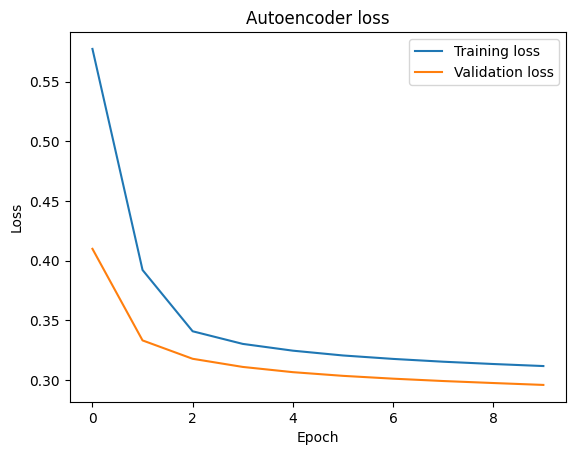

In [25]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Autoencoder loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()